# Formula 1 Data Analysis (1950 - 2024)
**Unit 3 Final Project - Tuwaiq Academy**

Name: Mohammad Ahmad Abutalib

## Contents
1. Introduction
2. Loading the data
3. Data exploration
4. Data cleaning
5. EDA
6. Model
7. Insights
8. Conclusion
9. References

## 1. Introduction

**Dataset:** Formula 1 World Championship (1950 - 2024)

**Source:** https://github.com/raceoptidata/Ergast_like-dumps (same data as the Kaggle dataset:
https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020)

**Description:** The dataset has every F1 race from 1950 to 2024. It is split into several CSV files:
races, results, drivers, constructors (teams), circuits and status. The results file has one row for every driver
in every race, with the starting position, finishing position, points and how the race ended.

**Why I chose it:** I like Formula 1, and the data covers 75 years of history. It also comes in several tables,
so I had to merge them, which was good practice.

### Problem definition
Questions I want to answer:
1. How did the number of races change over the years?
2. Did cars become more reliable (fewer cars not finishing)?
3. Who are the drivers and teams with the most wins?
4. How important is the starting position? Does pole position usually win?
5. Are F1 drivers getting younger?
6. Which countries have the most drivers and wins?

What I expect:
- More races per season now than in the past.
- Many more cars finishing races today.
- Hamilton and Schumacher with the most wins, and Ferrari as the top team.
- Starting at the front is a big advantage.

## 2. Loading the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
os.makedirs("figures", exist_ok=True)

In [2]:
url = "https://raw.githubusercontent.com/raceoptidata/Ergast_like-dumps/main/samples/"

# missing values are written as "NULL" in these files
results = pd.read_csv(url + "results.csv", na_values="NULL")
races = pd.read_csv(url + "races.csv", na_values="NULL")
drivers = pd.read_csv(url + "drivers.csv", na_values="NULL")
constructors = pd.read_csv(url + "constructors.csv", na_values="NULL")
circuits = pd.read_csv(url + "circuits.csv", na_values="NULL")
status = pd.read_csv(url + "status.csv", na_values="NULL")

print("results:", results.shape)
print("races:", races.shape)
print("drivers:", drivers.shape)
print("constructors:", constructors.shape)
print("circuits:", circuits.shape)
print("status:", status.shape)

results: (26759, 18)
races: (1125, 18)
drivers: (864, 9)
constructors: (212, 5)
circuits: (77, 9)
status: (141, 2)


## 3. Data exploration
The main file is `results`. The other files explain the ID columns (raceId, driverId, constructorId, statusId).

In [3]:
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


In [4]:
results.shape

(26759, 18)

In [5]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

In [6]:
results.describe()

,resultId,raceId,driverId,constructorId,number,grid,position,positionOrder,points,laps,milliseconds,fastestLap,rank,fastestLapSpeed,statusId
count,26759.000000,26759.000000,26759.000000,26759.000000,26753.000000,26759.000000,15806.000000,26759.000000,26759.000000,26759.000000,7.680000e+03,8252.000000,8510.000000,8252.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,18.153927,11.134796,8.020499,12.794051,1.987632,46.301768,6.185833e+06,42.732913,10.334313,204.116330,17.224971
std,7726.134642,313.265036,282.703039,61.551498,15.581135,7.202860,4.840796,7.665951,4.351209,29.496557,1.669306e+06,16.603460,6.140957,21.377265,26.026104
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,5.260000e+02,1.000000,0.000000,89.540000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,7.000000,5.000000,4.000000,6.000000,0.000000,23.000000,5.378454e+06,33.000000,5.000000,193.322500,1.000000
50%,13380.000000,531.000000,172.000000,25.000000,16.000000,11.000000,8.000000,12.000000,0.000000,53.000000,5.788194e+06,46.000000,10.000000,204.894000,10.000000
75%,20069.500000,811.000000,399.500000,63.000000,24.000000,17.000000,11.000000,18.000000,2.000000,66.000000,6.402676e+06,54.000000,15.000000,217.324000,14.000000
max,26764.000000,1144.000000,862.000000,215.000000,208.000000,34.000000,33.000000,39.000000,50.000000,200.000000,1.509054e+07,85.000000,24.000000,257.320000,141.000000


In [7]:
results.isnull().sum()

,0
resultId,0
raceId,0
driverId,0
constructorId,0
number,6
grid,0
position,10953
positionText,0
positionOrder,0
points,0


In [8]:
# check duplicates
results.duplicated().sum()

np.int64(0)

In [9]:
# how did the races end? (statusId -> status text)
results.merge(status, on="statusId")["status"].value_counts().head(15)

,count
status,
Finished,7674
+1 Lap,4037
Engine,2026
+2 Laps,1613
Accident,1062
Did not qualify,1025
Collision,854
Gearbox,810
Spun off,795


**Notes from exploring:**
- No duplicate rows.
- `position` is empty for ~40% of rows. This is normal, it is empty when the driver did not finish.
  `positionOrder` always has the final order so I will use that.
- `time`, `fastestLap` etc. are mostly empty (only recorded in recent years), so I won't use them.
- Some rows are drivers who **did not qualify** or **withdrew**, so they never actually raced. I will remove them.
- `grid = 0` means the driver started from the pit lane, not from 1st place, so I will change 0 to missing.
- There are 140 different statuses, so I will group them into: Finished, Accident, Mechanical, Other.

## 4. Data cleaning
First I merge the tables into one dataframe.

In [10]:
# keep only the columns I need from each table
races = races[["raceId", "year", "round", "circuitId", "name", "date"]]
races = races.rename(columns={"name": "race"})

drivers = drivers[["driverId", "forename", "surname", "dob", "nationality"]]

constructors = constructors[["constructorId", "name"]]
constructors = constructors.rename(columns={"name": "team"})

circuits = circuits[["circuitId", "name", "country", "lat", "lng"]]
circuits = circuits.rename(columns={"name": "circuit"})

results = results[["raceId", "driverId", "constructorId", "grid", "positionOrder", "points", "laps", "statusId"]]

df = results.merge(races, on="raceId")
df = df.merge(drivers, on="driverId")
df = df.merge(constructors, on="constructorId")
df = df.merge(circuits, on="circuitId")
df = df.merge(status, on="statusId")

print(df.shape)
df.head()

(26759, 23)


,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId,year,round,...,forename,surname,dob,nationality,team,circuit,country,lat,lng,status
0,18,1,1,1,1,10.0,58,1,2008,1,...,Lewis,Hamilton,1985-01-07,British,McLaren,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Finished
1,18,2,2,5,2,8.0,58,1,2008,1,...,Nick,Heidfeld,1977-05-10,German,BMW Sauber,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Finished
2,18,3,3,7,3,6.0,58,1,2008,1,...,Nico,Rosberg,1985-06-27,German,Williams,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Finished
3,18,4,4,11,4,5.0,58,1,2008,1,...,Fernando,Alonso,1981-07-29,Spanish,Renault,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Finished
4,18,5,1,3,5,4.0,58,1,2008,1,...,Heikki,Kovalainen,1981-10-19,Finnish,McLaren,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Finished


In [11]:
# rename columns
df = df.rename(columns={"positionOrder": "position"})
df["driver"] = df["forename"] + " " + df["surname"]

# remove drivers who never started the race
print("rows before:", len(df))
df = df[~df["status"].isin(["Did not qualify", "Did not prequalify", "Withdrew"])]
print("rows after:", len(df))

rows before: 26759
rows after: 25155


In [12]:
# grid = 0 means pit lane start -> set as missing
df["grid"] = df["grid"].replace(0, np.nan)

# convert dates
df["date"] = pd.to_datetime(df["date"])
df["dob"] = pd.to_datetime(df["dob"])

# remove duplicates (just in case)
df = df.drop_duplicates()

df.isnull().sum()

,0
raceId,0
driverId,0
constructorId,0
grid,130
position,0
points,0
laps,0
statusId,0
year,0
round,0


In [13]:
# group the statuses into 4 types
accidents = ["Accident", "Collision", "Spun off", "Collision damage", "Fatal accident", "Damage", "Debris"]
other = ["Disqualified", "Excluded", "Not classified", "Retired", "Physical", "Injured", "Illness",
         "Driver unwell", "Did not start", "Not restarted", "Injury", "Eye injury", "Underweight", "Safety concerns"]

def get_result(s):
    if s == "Finished" or s.startswith("+"):   # "+1 Lap", "+2 Laps" still finished
        return "Finished"
    elif s in accidents:
        return "Accident"
    elif s in other:
        return "Other"
    else:
        return "Mechanical"   # engine, gearbox, brakes...

df["result"] = df["status"].apply(get_result)
df["result"].value_counts()

,count
result,
Finished,15161
Mechanical,6714
Accident,2777
Other,503


### New columns

In [14]:
df["decade"] = (df["year"] // 10 * 10).astype(str) + "s"
df["age"] = (df["date"] - df["dob"]).dt.days / 365.25
df["finished"] = df["result"] == "Finished"
df["win"] = df["position"] == 1
df["podium"] = df["position"] <= 3
df["pole"] = df["grid"] == 1

# keep the useful columns
df = df[["year", "decade", "round", "race", "date", "circuit", "country", "lat", "lng", "driver", "nationality",
         "age", "team", "grid", "position", "points", "laps", "status", "result", "finished", "win", "podium", "pole"]]
df.head()

,year,decade,round,race,date,circuit,country,lat,lng,driver,...,grid,position,points,laps,status,result,finished,win,podium,pole
0,2008,2000s,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Lewis Hamilton,...,1.0,1,10.0,58,Finished,Finished,True,True,True,True
1,2008,2000s,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Nick Heidfeld,...,5.0,2,8.0,58,Finished,Finished,True,False,True,False
2,2008,2000s,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Nico Rosberg,...,7.0,3,6.0,58,Finished,Finished,True,False,True,False
3,2008,2000s,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Fernando Alonso,...,11.0,4,5.0,58,Finished,Finished,True,False,False,False
4,2008,2000s,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,-37.8497,144.968,Heikki Kovalainen,...,3.0,5,4.0,58,Finished,Finished,True,False,False,False


In [15]:
# save the clean data
df.to_csv("clean_data.csv", index=False)
os.makedirs("streamlit_app", exist_ok=True)
df.to_csv("streamlit_app/clean_data.csv", index=False)
print(df.shape)

(25155, 23)


## 5. EDA
For the main questions from my problem definition, I wrote what I expected before the graph and checked it after.

### Univariate

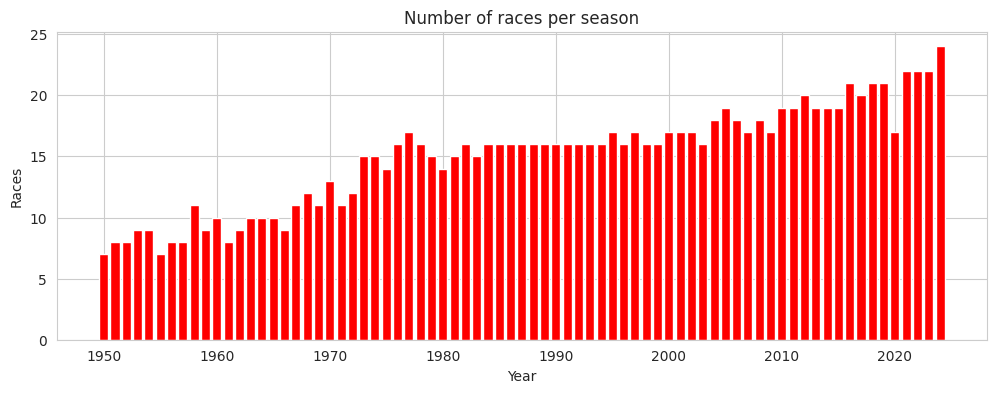

In [16]:
races_per_year = df.groupby("year")["race"].nunique()

plt.figure(figsize=(12, 4))
plt.bar(races_per_year.index, races_per_year.values, color="red")
plt.title("Number of races per season")
plt.xlabel("Year")
plt.ylabel("Races")
plt.savefig("figures/races_per_season.png")
plt.show()

The calendar grew from 7 races in 1950 to 24 in 2024, more than 3 times bigger. The biggest growth came after 2000.

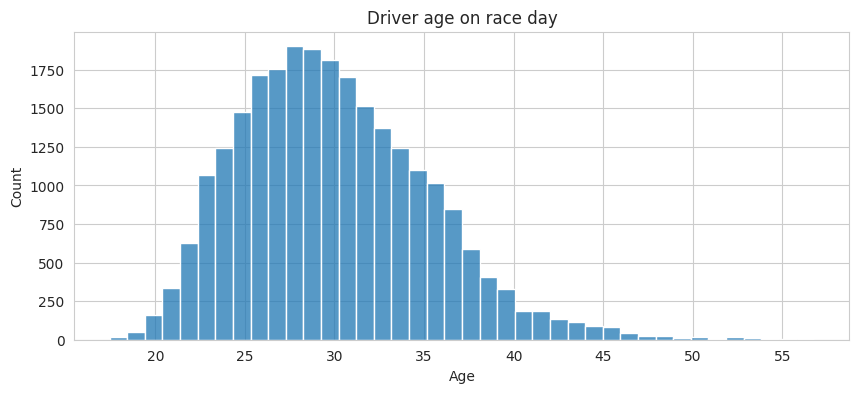

,age
count,25155.000000
mean,29.983628
std,5.282684
min,17.453799
25%,26.099932
50%,29.437372
75%,33.321013
max,56.774812


In [17]:
plt.figure(figsize=(10, 4))
sns.histplot(df["age"], bins=40)
plt.title("Driver age on race day")
plt.xlabel("Age")
plt.savefig("figures/age_hist.png")
plt.show()

df["age"].describe()

Most drivers are between 26 and 33 years old (median 29.4). There is a long tail of older drivers on the right.

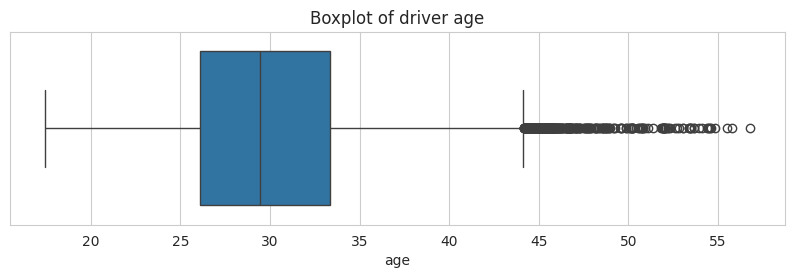

outlier limit: 44.2
outliers: 323 = 1.3 % of entries
% of outliers before 1975: 99.4


In [18]:
plt.figure(figsize=(10, 2.5))
sns.boxplot(x=df["age"])
plt.title("Boxplot of driver age")
plt.show()

# outliers with the IQR rule
q1 = df["age"].quantile(0.25)
q3 = df["age"].quantile(0.75)
limit = q3 + 1.5 * (q3 - q1)
old = df[df["age"] > limit]
print("outlier limit:", round(limit, 1))
print("outliers:", len(old), "=", round(len(old) / len(df) * 100, 1), "% of entries")
print("% of outliers before 1975:", round((old["year"] < 1975).mean() * 100, 1))

Ages above 44 are outliers. They are only 1.3% of entries and almost all of them (99%) are from before 1975, when older drivers were common. They are real, so I kept them.

**Hypothesis:** Most cars finish the race, and when they don't, accidents are the main reason.

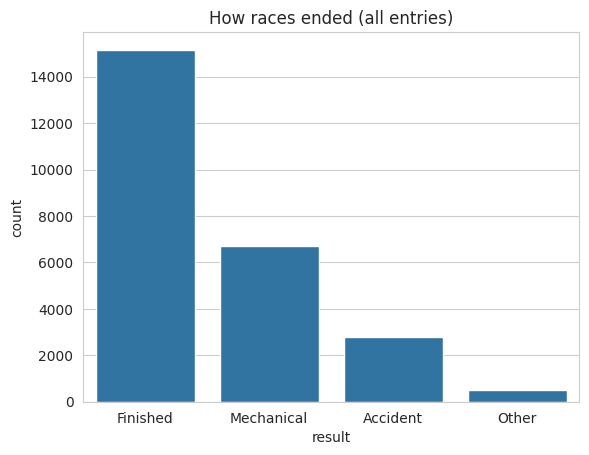

,proportion
result,
Finished,60.270324
Mechanical,26.690519
Accident,11.039555
Other,1.999602


In [19]:
sns.countplot(x="result", data=df, order=df["result"].value_counts().index)
plt.title("How races ended (all entries)")
plt.savefig("figures/results_count.png")
plt.show()

df["result"].value_counts(normalize=True) * 100

**Answer: ⚠️ Partly true.** 60% of entries finished, so most cars do finish. But the main reason for not finishing is **mechanical problems** (27%), not accidents (11%). I was wrong about that part.

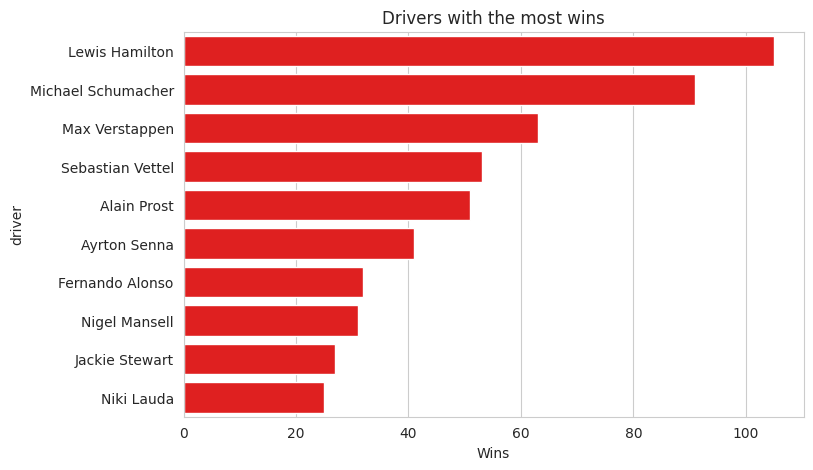

,count
driver,
Lewis Hamilton,105
Michael Schumacher,91
Max Verstappen,63
Sebastian Vettel,53
Alain Prost,51
Ayrton Senna,41
Fernando Alonso,32
Nigel Mansell,31
Jackie Stewart,27


In [20]:
top_drivers = df[df["win"]]["driver"].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_drivers.values, y=top_drivers.index, color="red")
plt.title("Drivers with the most wins")
plt.xlabel("Wins")
plt.savefig("figures/top_drivers.png")
plt.show()
top_drivers

Hamilton has the most wins (105), then Schumacher (91) and Verstappen (63). Only 115 of the 789 drivers in history ever won a race.

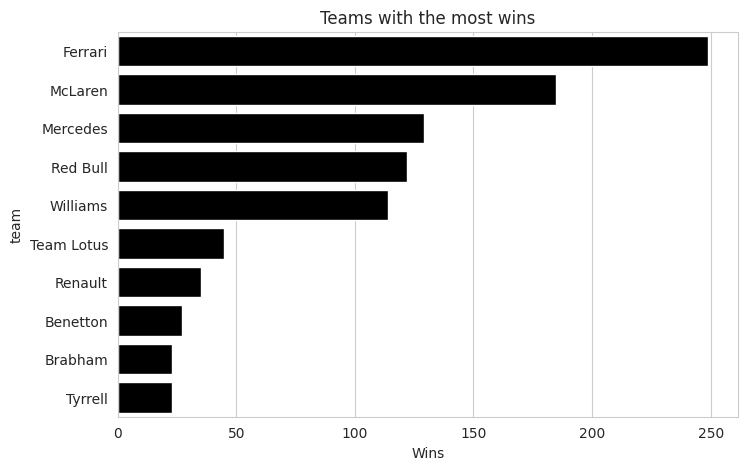

,count
team,
Ferrari,249
McLaren,185
Mercedes,129
Red Bull,122
Williams,114
Team Lotus,45
Renault,35
Benetton,27
Brabham,23


In [21]:
top_teams = df[df["win"]]["team"].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_teams.values, y=top_teams.index, color="black")
plt.title("Teams with the most wins")
plt.xlabel("Wins")
plt.savefig("figures/top_teams.png")
plt.show()
top_teams

Ferrari has 249 wins, well ahead of McLaren (185) and Mercedes (129).

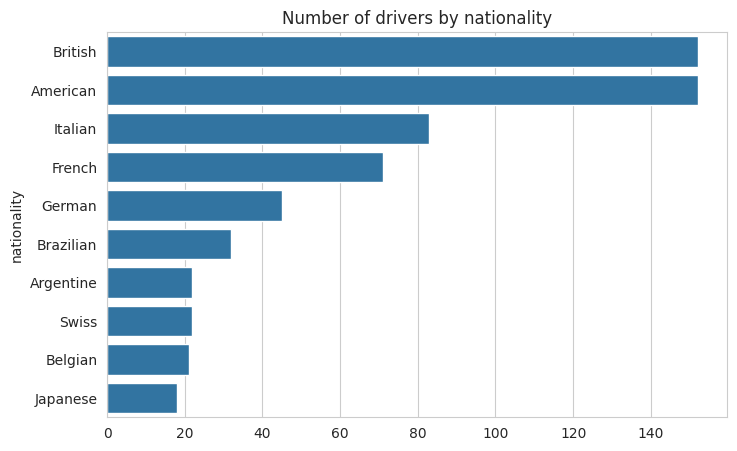

,count
nationality,
British,152
American,152
Italian,83
French,71
German,45
Brazilian,32
Argentine,22
Swiss,22
Belgian,21


In [22]:
# count each driver once
nat = df.drop_duplicates("driver")["nationality"].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=nat.values, y=nat.index)
plt.title("Number of drivers by nationality")
plt.show()
nat

Britain and the USA are tied with 152 drivers each. The USA number surprised me: it's high because the Indianapolis 500 was part of the championship from 1950 to 1960, so many American drivers are counted. Italy is third with 83.

### Bivariate / multivariate

**Hypothesis:** Cars have become more reliable, so the % of cars that finish should go up over time.

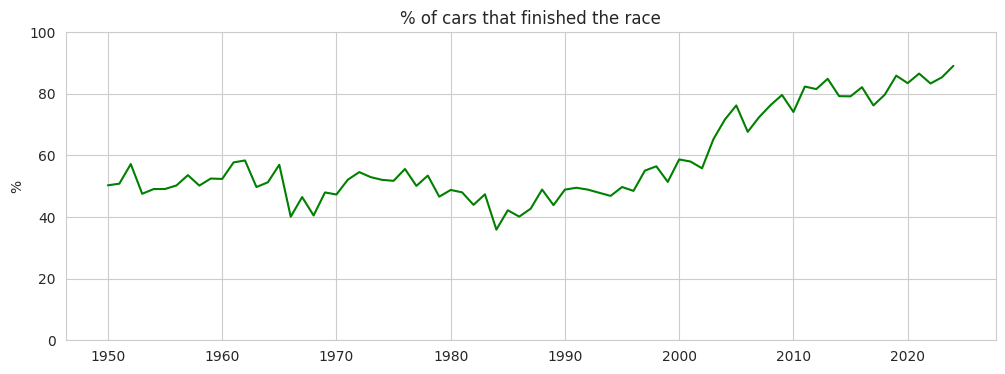

year
1950    50.3
1984    35.9
2000    58.7
2024    89.1
Name: finished, dtype: float64


In [23]:
finish_rate = df.groupby("year")["finished"].mean() * 100

plt.figure(figsize=(12, 4))
plt.plot(finish_rate.index, finish_rate.values, color="green")
plt.title("% of cars that finished the race")
plt.ylabel("%")
plt.ylim(0, 100)
plt.savefig("figures/finish_rate.png")
plt.show()

print(finish_rate[[1950, 1984, 2000, 2024]].round(1))

**Answer:  Partly true.** It did go up, but not steadily. From 1950 to the late 1990s it stayed around 50%, and it even dropped to its lowest point in 1984 (36%). The big improvement only started around 2000, reaching 89% in 2024.

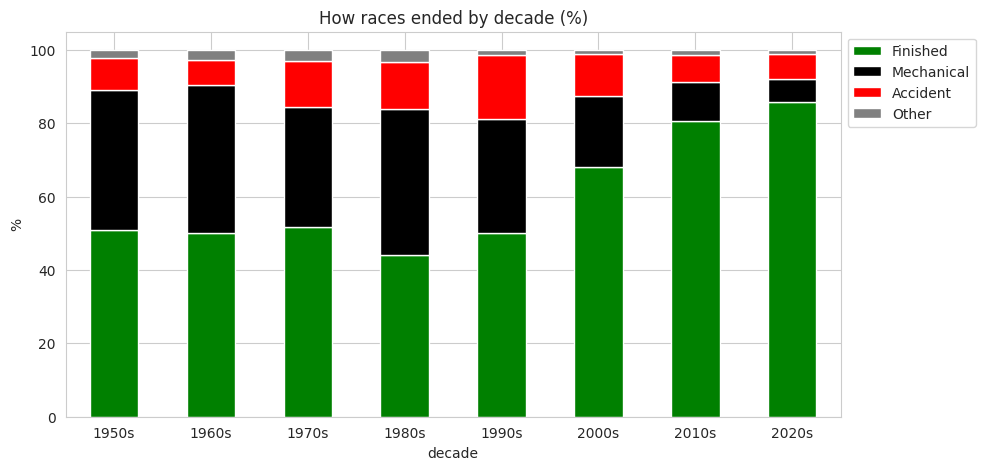

result,Finished,Mechanical,Accident,Other
decade,,,,
1950s,51.0,38.3,8.6,2.2
1960s,50.1,40.4,6.7,2.8
1970s,51.8,32.6,12.5,3.1
1980s,44.1,39.9,12.9,3.1
1990s,50.2,31.1,17.4,1.4
2000s,68.1,19.4,11.4,1.1
2010s,80.6,10.7,7.3,1.4
2020s,85.7,6.4,6.7,1.1


In [24]:
table = pd.crosstab(df["decade"], df["result"], normalize="index") * 100
table = table[["Finished", "Mechanical", "Accident", "Other"]]

table.plot(kind="bar", stacked=True, figsize=(10, 5), color=["green", "black", "red", "grey"])
plt.title("How races ended by decade (%)")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))
plt.savefig("figures/result_by_decade.png")
plt.show()
table.round(1)

This shows the reason behind the graph above: mechanical failures were 30–40% of entries from the 1950s to the 1990s and only 6% in the 2020s. Accidents peaked in the 1990s (17%) and are now about 7%.

**Hypothesis:** Starting from pole gives the best chance of winning, and the chance drops quickly further back.

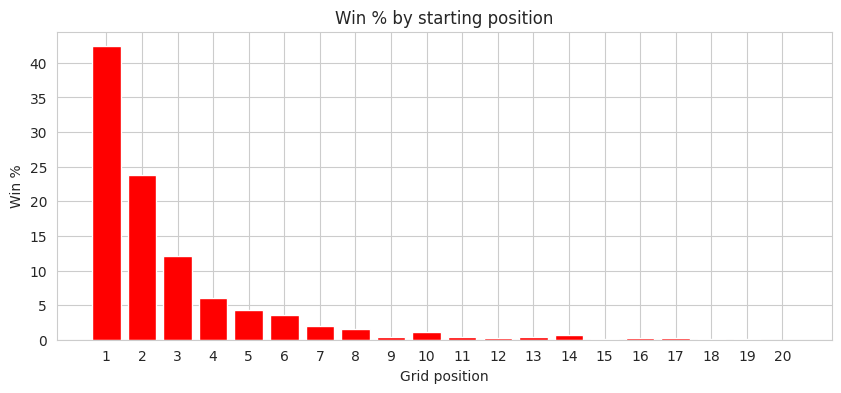

,win
grid,
1.0,42.4
2.0,23.9
3.0,12.1
4.0,6.0
5.0,4.3


In [25]:
front = df[df["grid"] <= 20]
win_rate = front.groupby("grid")["win"].mean() * 100

plt.figure(figsize=(10, 4))
plt.bar(win_rate.index, win_rate.values, color="red")
plt.title("Win % by starting position")
plt.xlabel("Grid position")
plt.ylabel("Win %")
plt.xticks(range(1, 21))
plt.savefig("figures/win_by_grid.png")
plt.show()

win_rate.head(5).round(1)

**Answer:  Confirmed.** Pole wins 42% of races, 2nd place 24% and 3rd 12%. From 5th place back the chance is under 5%.

**Hypothesis:** In modern F1, overtaking is harder, so more races are won from pole than in the past.

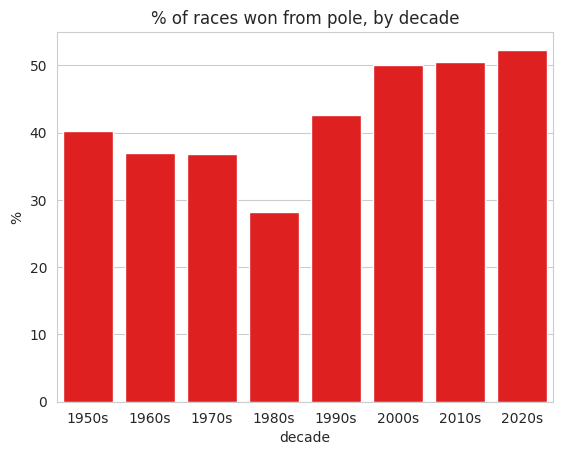

,pole
decade,
1950s,40.2
1960s,37.0
1970s,36.8
1980s,28.2
1990s,42.6
2000s,50.0
2010s,50.5
2020s,52.3


In [26]:
winners = df[df["win"]]
pole_wins = winners.groupby("decade")["pole"].mean() * 100

sns.barplot(x=pole_wins.index, y=pole_wins.values, color="red")
plt.title("% of races won from pole, by decade")
plt.ylabel("%")
plt.show()
pole_wins.round(1)

**Answer:  Confirmed.** In the 1980s only 28% of races were won from pole. Since 2000 it's about 50%, so qualifying became much more important.

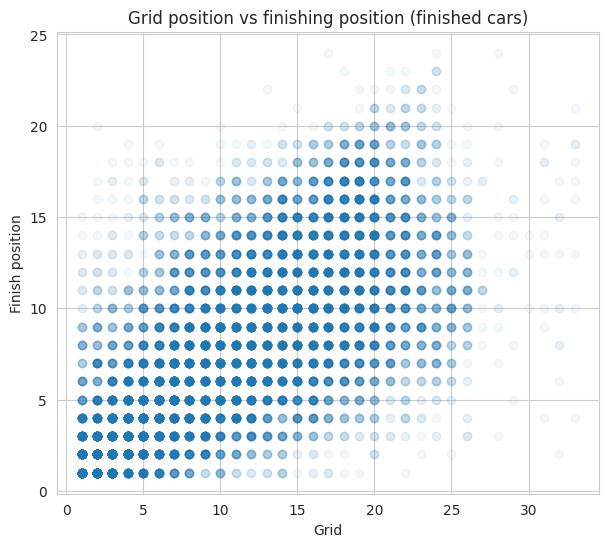

correlation: 0.68


In [27]:
finished = df[df["finished"]]

plt.figure(figsize=(7, 6))
plt.scatter(finished["grid"], finished["position"], alpha=0.05)
plt.title("Grid position vs finishing position (finished cars)")
plt.xlabel("Grid")
plt.ylabel("Finish position")
plt.savefig("figures/grid_vs_finish.png")
plt.show()

print("correlation:", finished["grid"].corr(finished["position"]).round(2))

Most cars finish close to where they started: the points are concentrated near the diagonal and the correlation is 0.68. Big comebacks from the back happen but they are rare.

**Hypothesis:** In some seasons one team won almost every race.

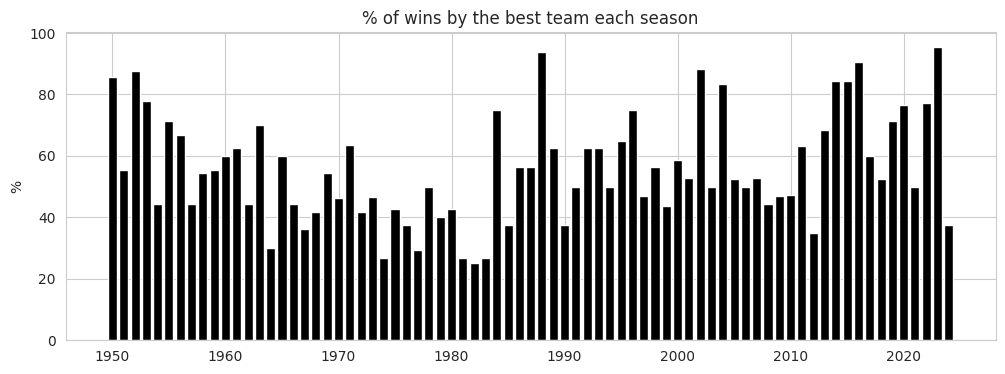

,year,team,wins,percent
272,2023,Red Bull,21,95.454545
157,1988,McLaren,15,93.750000
249,2016,Mercedes,19,90.476190
200,2002,Ferrari,15,88.235294
5,1952,Ferrari,7,87.500000


In [28]:
# which team won the most races each season, and what % of the races
wins_per_team = winners.groupby(["year", "team"]).size().reset_index(name="wins")
races_count = winners.groupby("year").size()
wins_per_team["percent"] = wins_per_team["wins"] / wins_per_team["year"].map(races_count) * 100

best_team = wins_per_team.sort_values("percent", ascending=False).drop_duplicates("year").sort_values("year")

plt.figure(figsize=(12, 4))
plt.bar(best_team["year"], best_team["percent"], color="black")
plt.title("% of wins by the best team each season")
plt.ylabel("%")
plt.savefig("figures/dominance.png")
plt.show()

best_team.sort_values("percent", ascending=False).head(5)

**Answer:  Confirmed.** Red Bull won 95% of races in 2023 (21 of 22), the most dominant season ever. McLaren in 1988 (94%) and Mercedes in 2016 (90%) are next.

**Hypothesis:** Race winners are younger today than in the past.

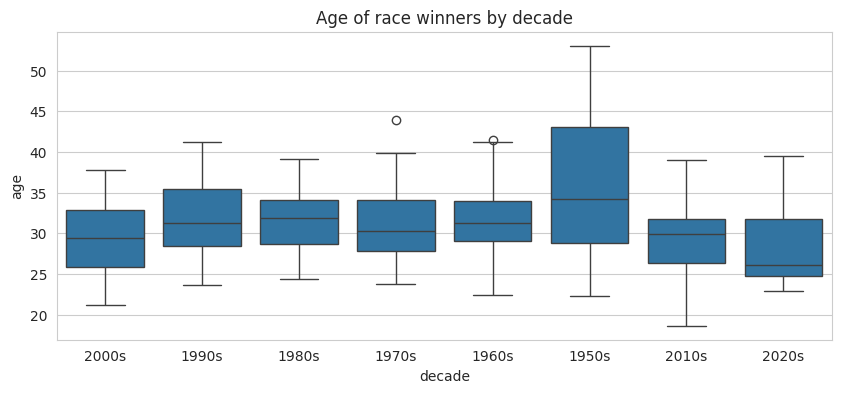

,age
decade,
1950s,34.2
1960s,31.3
1970s,30.2
1980s,31.8
1990s,31.3
2000s,29.4
2010s,29.9
2020s,26.1


In [29]:
plt.figure(figsize=(10, 4))
sns.boxplot(x="decade", y="age", data=winners)
plt.title("Age of race winners by decade")
plt.show()

winners.groupby("decade")["age"].median().round(1)

**Answer:  Confirmed.** The median winner was 34 in the 1950s and 26 in the 2020s. The 2020s is the youngest decade by far.

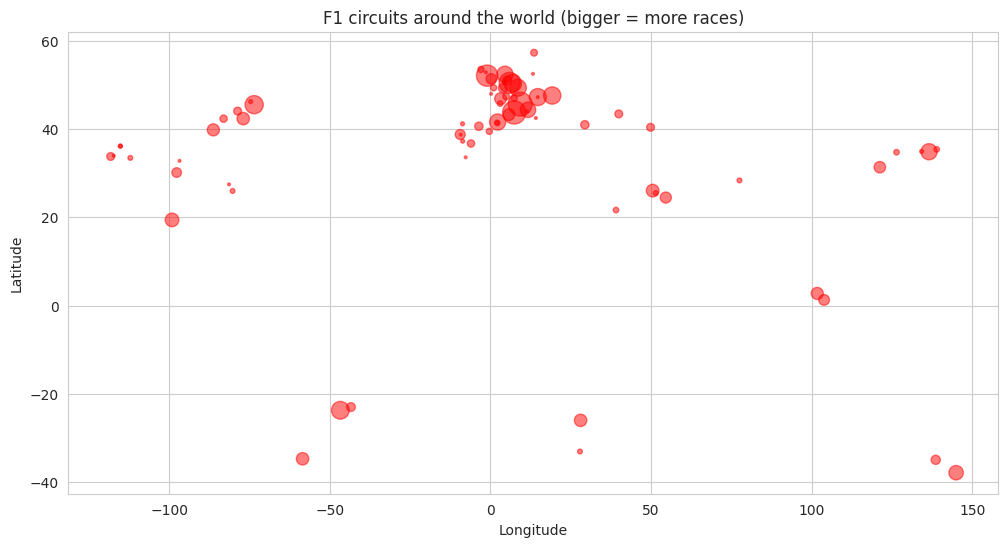

% of races in Europe: 60.3


,circuit,races
7,Autodromo Nazionale di Monza,74
25,Circuit de Monaco,70
69,Silverstone Circuit,59
28,Circuit de Spa-Francorchamps,57
20,Circuit Gilles Villeneuve,43


In [30]:
# one row per race, then count races at each circuit
circ = df.drop_duplicates("date").groupby(["circuit", "lat", "lng"]).size().reset_index(name="races")

plt.figure(figsize=(12, 6))
plt.scatter(circ["lng"], circ["lat"], s=circ["races"] * 4, color="red", alpha=0.5)
plt.title("F1 circuits around the world (bigger = more races)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.savefig("figures/circuits_map.png")
plt.show()

# rough box around Europe on the map
races_only = df.drop_duplicates("date")
europe = races_only["lng"].between(-10, 30) & races_only["lat"].between(35, 60)
print("% of races in Europe:", round(europe.mean() * 100, 1))

circ.sort_values("races", ascending=False)[["circuit", "races"]].head(5)

About 60% of all races were held in Europe. Monza (74 races) and Monaco (70) have hosted the most. Newer circuits are spread across Asia, the Middle East and the Americas.

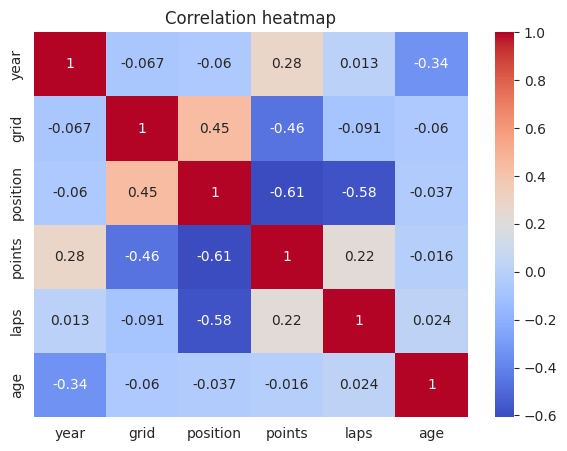

In [31]:
cols = ["year", "grid", "position", "points", "laps", "age"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation heatmap")
plt.savefig("figures/heatmap.png")
plt.show()

Finishing position has the strongest link with points (−0.61) and laps (−0.58, cars that retire early are classified lower). Grid position is also linked to finishing position (0.45) and points (−0.46). Year and age are negatively correlated (−0.34), so drivers got younger over time.

### Outliers

In [32]:
print("Oldest drivers:")
display(df.sort_values("age", ascending=False)[["driver", "year", "race", "age"]].head())

print("Youngest drivers:")
display(df.sort_values("age")[["driver", "year", "race", "age"]].head())

Oldest drivers:


,driver,year,race,age
18912,Louis Chiron,1956,Monaco Grand Prix,56.774812
19082,Louis Chiron,1955,Monaco Grand Prix,55.797399
19722,Philippe Étancelin,1952,French Grand Prix,55.518138
20011,Philippe Étancelin,1951,Spanish Grand Prix,54.828200
19502,Arthur Legat,1953,Belgian Grand Prix,54.633812


Youngest drivers:


,driver,year,race,age
22546,Max Verstappen,2015,Australian Grand Prix,17.453799
22558,Max Verstappen,2015,Malaysian Grand Prix,17.492129
22588,Max Verstappen,2015,Chinese Grand Prix,17.530459
22609,Max Verstappen,2015,Bahrain Grand Prix,17.549624
22622,Max Verstappen,2015,Spanish Grand Prix,17.607118


The oldest driver was Louis Chiron at 56 in 1956, and the youngest was Max Verstappen at 17 in 2015. These are real, so I kept them.

## 6. Model (optional)
I tried to predict if a driver finishes on the podium (top 3) using the starting position, the year and the driver's age.

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import joblib

data = df.dropna(subset=["grid"])
X = data[["grid", "year", "age"]]
y = data["podium"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("Baseline (always 'no podium'):", round(1 - y_test.mean(), 3))
print(classification_report(y_test, pred))

Accuracy: 0.891
Baseline (always 'no podium'): 0.872
              precision    recall  f1-score   support

       False       0.91      0.97      0.94      4362
        True       0.64      0.36      0.46       643

    accuracy                           0.89      5005
   macro avg       0.77      0.66      0.70      5005
weighted avg       0.88      0.89      0.88      5005



In [34]:
# save model for the dashboard
joblib.dump(model, "streamlit_app/model.joblib")

# try an example: starting 1st vs 10th in 2024, age 27
example = pd.DataFrame({"grid": [1, 10], "year": [2024, 2024], "age": [27, 27]})
model.predict_proba(example)[:, 1]

array([0.769407  , 0.05889598])

## 7. Insights
**Patterns**
- F1 grew from 7 races in 1950 to 24 in 2024.
- Lewis Hamilton has the most wins (105), then Michael Schumacher (91) and Max Verstappen (63). Ferrari is the most successful team with 249 wins.
- Only 115 of 789 drivers ever won a race.
- Britain has produced the most drivers and the most wins.

**Relationships**
- Reliability improved a lot: around 50% of cars finished until the late 90s, almost 90% in 2024.
- Starting position matters a lot: pole wins 42% of the time, and since 2000 about half of all races are won from pole.
- Grid and finishing position are strongly correlated for cars that finish (0.68).
- Some seasons had one team winning almost everything (Red Bull 2023: 95% of races).
- Winners are younger now (median 26 in the 2020s vs 34 in the 1950s).

**Outliers**
- Very old drivers (up to 56) in the 1950s and the youngest ever, Verstappen at 17. They are real, so I kept them.

**Model**
- The model is 89% accurate, but always guessing "no podium" already gives 87%, so it only improves a little. It finds about a third of the podiums. Starting position alone is not enough to predict podiums well, since team strength also matters (a future improvement).
- Example: a driver starting 1st in 2024 gets a 77% podium chance, starting 10th only 6%.

## 8. Conclusion

**What I learned**
- How to merge several tables into one using IDs.
- Missing values are not always errors (an empty finishing position just means the driver did not finish).
- Grouping many categories (140 statuses) into a few makes them much easier to analyse.
- A simple rule can be almost as good as a model, so it's important to compare with a baseline.

**Limitations**
- The rules changed a lot over the years (points system, number of cars, race length), so comparing eras is not always fair. That's why I used wins and podiums instead of points.
- The Indianapolis 500 (1950 - 1960) was a different type of race but it's counted in the data.
- No weather or tyre data, and lap times only exist from 2004.
- Teams that changed names (like Brawn -> Mercedes) count as different teams.

**Future work**
- Use the lap time and pit stop files to study race strategy.
- Add weather data.
- Compare teammates in qualifying to rank drivers more fairly.

## 9. References
- RaceOptiData F1 data: https://github.com/raceoptidata/Ergast_like-dumps
- Kaggle F1 dataset: https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020
